# Turbofan Engine RUL Prediction with an LSTM (NASA C-MAPSS FD004)


**Goal:** predict the *Remaining Useful Life* (RUL, in cycles) of a jet engine from its sensor history.

**Pipeline**

1. Setup and configuration
2. Load the data
3. Exploratory data analysis
4. Cleaning and RUL labels
5. Feature engineering (rolling means)
6. Split by engine (train / validation)
7. Scaling (fit on training engines only)
8. Build 30-cycle sequences
9. Build and train the LSTM
10. Validation results
11. Final test results (official `RUL_FD004.txt`)
12. Save the model and a reusable inference function

## 1. Setup and configuration

In [1]:
import os
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam

warnings.filterwarnings("ignore", category=UserWarning)

# ---------------- Configuration (change things here only) ----------------
DATASET       = "FD004"
SEQ_LEN       = 30      # cycles per LSTM input window
ROLL_WINDOW   = 15      # rolling-mean window
MAX_RUL       = 125     # RUL is clipped at this value (piece-wise linear RUL)
VAL_FRACTION  = 0.20    # share of engines used for validation
USE_SETTINGS  = False   # FD003 has one operating condition, so settings are mostly noise
EPOCHS        = int(os.environ.get("EPOCHS", 50))
BATCH_SIZE    = 64
SEED          = 42
OUTPUT_DIR    = Path("outputs")
# --------------------------------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)
print("Config:", dict(SEQ_LEN=SEQ_LEN, ROLL_WINDOW=ROLL_WINDOW, MAX_RUL=MAX_RUL,
                      USE_SETTINGS=USE_SETTINGS, EPOCHS=EPOCHS))


TensorFlow: 2.15.0
Config: {'SEQ_LEN': 30, 'ROLL_WINDOW': 15, 'MAX_RUL': 125, 'USE_SETTINGS': False, 'EPOCHS': 50}


## 2. Load the data
The notebook looks for the three files (`train_FD004.txt`, `test_FD004.txt`, `RUL_FD004.txt`) in the current
folder and a few common sub-folders (`data`, `CMaps`, `CMAPSSData`).
You can also point to the folder yourself by setting the environment variable `CMAPSS_DIR`.

In [2]:
def find_data_dir(filename=f"train_{DATASET}.txt"):
    candidates = [
    r"D:\Learning\NTI-HireReady AI in DA\TECHNICAL\NASA_PROJECT\FD004",
    ".", os.environ.get("CMAPSS_DIR"), "data", "CMaps", "CMAPSSData", "../CMaps",
]
    for c in candidates:
        if c and (Path(c) / filename).exists():
            return Path(c)
    print("Current folder:", Path(".").resolve())
    print("Files here:", sorted(p.name for p in Path(".").iterdir()))
    raise FileNotFoundError(
        f"Could not find {filename}. Put the C-MAPSS files next to this notebook "
        "or set the CMAPSS_DIR environment variable to their folder."
    )

DATA_DIR = find_data_dir()
print("Using data folder:", DATA_DIR.resolve())

index_names   = ["unit_number", "time_cycle"]
setting_names = ["altitude_setting", "mach_setting", "throttle_resolver_setting"]
sensor_names  = [
    "fan_inlet_temp", "LPC_outlet_temp", "HPC_outlet_temp", "LPT_outlet_temp",
    "fan_inlet_pressure", "bypass_duct_pressure", "HPC_outlet_pressure",
    "physical_fan_speed", "physical_core_speed", "engine_pressure_ratio",
    "HPC_static_pressure", "fuel_flow_ratio", "corrected_fan_speed",
    "corrected_core_speed", "bypass_ratio", "burner_fuel_air_ratio",
    "bleed_enthalpy", "demanded_fan_speed", "demanded_corrected_fan_speed",
    "HPT_coolant_bleed", "LPT_coolant_bleed",
]
col_names = index_names + setting_names + sensor_names

def read_table(name, names):
    return pd.read_csv(DATA_DIR / name, sep=r"\s+", header=None, names=names)

data_train = read_table(f"train_{DATASET}.txt", col_names)
data_test  = read_table(f"test_{DATASET}.txt",  col_names)
data_rul   = read_table(f"RUL_{DATASET}.txt",   ["RUL"])

# Make every numeric column float so scaling later does not raise dtype warnings
num_cols = setting_names + sensor_names
data_train[num_cols] = data_train[num_cols].astype("float64")
data_test[num_cols]  = data_test[num_cols].astype("float64")

print("Train:", data_train.shape, "| Test:", data_test.shape, "| RUL:", data_rul.shape)
# Validate the number of engines in the test dataset
n_test_engines = data_test["unit_number"].nunique()
n_rul_values = len(data_rul)

print("Train engines:", data_train["unit_number"].nunique())
print("Test engines:", n_test_engines)
print("RUL values:", n_rul_values)

assert n_test_engines == n_rul_values, (
    f"Mismatch: {n_test_engines} test engines but "
    f"{n_rul_values} RUL values."
)

print("Validation passed: Test engines match RUL values.")

Using data folder: D:\Learning\NTI-HireReady AI in DA\TECHNICAL\NASA_PROJECT\FD004
Train: (61249, 26) | Test: (41214, 26) | RUL: (248, 1)
Train engines: 249
Test engines: 248
RUL values: 248
Validation passed: Test engines match RUL values.


## 3. Exploratory data analysis

Missing values  train / test / RUL: 0 / 0 / 0

Engines: 249
count    249.0
mean     246.0
std       73.1
min      128.0
25%      190.0
50%      234.0
75%      290.0
max      543.0


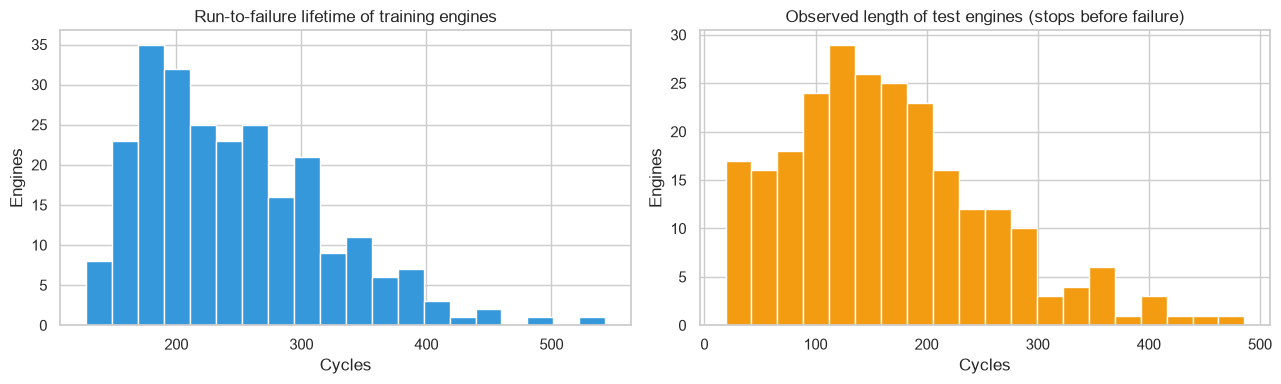

In [3]:
print("Missing values  train / test / RUL:",
      data_train.isnull().sum().sum(), "/", data_test.isnull().sum().sum(), "/", data_rul.isnull().sum().sum())

lifetimes = data_train.groupby("unit_number")["time_cycle"].max()
print(f"\nEngines: {len(lifetimes)}")
print(lifetimes.describe().round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(lifetimes, bins=20, color="#3498DB", edgecolor="white")
ax[0].set(title="Run-to-failure lifetime of training engines", xlabel="Cycles", ylabel="Engines")
test_len = data_test.groupby("unit_number")["time_cycle"].max()
ax[1].hist(test_len, bins=20, color="#F39C12", edgecolor="white")
ax[1].set(title="Observed length of test engines (stops before failure)", xlabel="Cycles", ylabel="Engines")
plt.tight_layout(); plt.show()

In [4]:
# Which columns carry no information? (a single unique value in the training data)
constant_cols = [c for c in setting_names + sensor_names if data_train[c].nunique() <= 1]
print("Constant columns removed:", constant_cols)

# Settings: only kept if USE_SETTINGS=True. In FD004 they are essentially noise.
kept_settings = [c for c in setting_names if c not in constant_cols] if USE_SETTINGS else []
kept_sensors  = [c for c in sensor_names  if c not in constant_cols]
base_features = kept_settings + kept_sensors
print(f"\nBase features kept ({len(base_features)}):", base_features)

Constant columns removed: []

Base features kept (21): ['fan_inlet_temp', 'LPC_outlet_temp', 'HPC_outlet_temp', 'LPT_outlet_temp', 'fan_inlet_pressure', 'bypass_duct_pressure', 'HPC_outlet_pressure', 'physical_fan_speed', 'physical_core_speed', 'engine_pressure_ratio', 'HPC_static_pressure', 'fuel_flow_ratio', 'corrected_fan_speed', 'corrected_core_speed', 'bypass_ratio', 'burner_fuel_air_ratio', 'bleed_enthalpy', 'demanded_fan_speed', 'demanded_corrected_fan_speed', 'HPT_coolant_bleed', 'LPT_coolant_bleed']


# 4. RUL labels

For each training engine, RUL at cycle *t* = (last cycle of that engine) − *t*.
Early in an engine's life the degradation is not visible in the sensors, so RUL is **clipped at 125**
(the standard piece-wise linear target). Without clipping, the model is asked to predict differences that the sensors cannot show.

,unit_number,time_cycle,RUL_raw,RUL
0,1,1,320,125
1,1,2,319,125
2,1,3,318,125
318,1,319,2,2
319,1,320,1,1
320,1,321,0,0


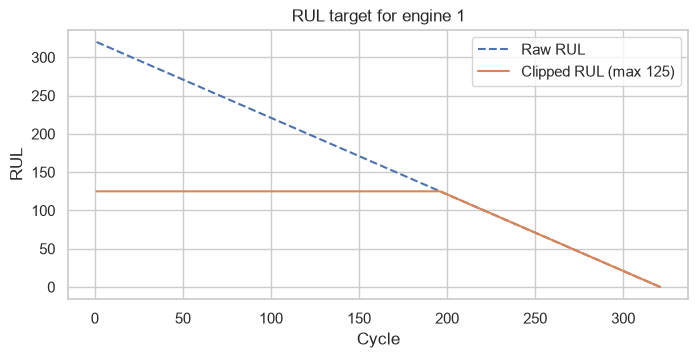

In [5]:
data_train = data_train.sort_values(["unit_number", "time_cycle"]).reset_index(drop=True)
data_test  = data_test.sort_values(["unit_number", "time_cycle"]).reset_index(drop=True)

last_cycle = data_train.groupby("unit_number")["time_cycle"].transform("max")
data_train["RUL_raw"] = last_cycle - data_train["time_cycle"]
data_train["RUL"]     = data_train["RUL_raw"].clip(upper=MAX_RUL)

display(data_train.loc[data_train["unit_number"] == 1, ["unit_number", "time_cycle", "RUL_raw", "RUL"]].iloc[[0, 1, 2, -3, -2, -1]])

e1 = data_train[data_train["unit_number"] == 1]
plt.figure(figsize=(8, 3.5))
plt.plot(e1["time_cycle"], e1["RUL_raw"], label="Raw RUL", linestyle="--")
plt.plot(e1["time_cycle"], e1["RUL"], label=f"Clipped RUL (max {MAX_RUL})")
plt.xlabel("Cycle"); plt.ylabel("RUL"); plt.title("RUL target for engine 1"); plt.legend(); plt.show()

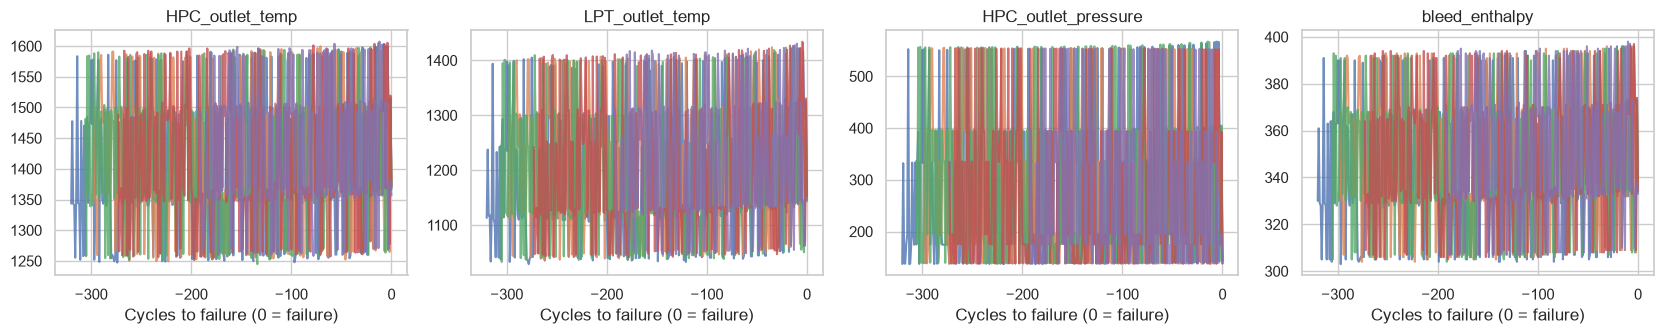

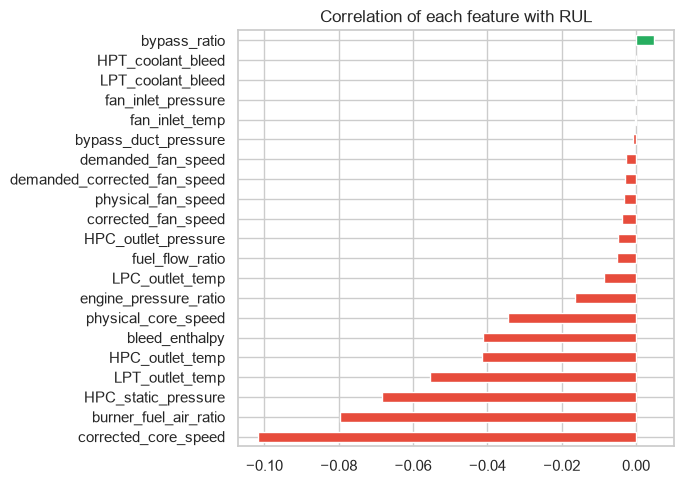

In [6]:
# Sensor behaviour over an engine's life (x-axis: cycles remaining, so failure is on the right)
plot_sensors = ["HPC_outlet_temp", "LPT_outlet_temp", "HPC_outlet_pressure", "bleed_enthalpy"]
plot_sensors = [s for s in plot_sensors if s in base_features]

fig, axes = plt.subplots(1, len(plot_sensors), figsize=(4.2 * len(plot_sensors), 3.5))
for ax, s in zip(np.atleast_1d(axes), plot_sensors):
    for u in [1, 2, 3, 4, 5]:
        d = data_train[data_train["unit_number"] == u]
        ax.plot(-d["RUL_raw"], d[s], alpha=0.8)
    ax.set(title=s, xlabel="Cycles to failure (0 = failure)")
plt.tight_layout(); plt.show()

# Correlation of each base feature with the (clipped) RUL
corr = data_train[base_features + ["RUL"]].corr()["RUL"].drop("RUL").sort_values()
plt.figure(figsize=(7, 5))
corr.plot.barh(color=np.where(corr < 0, "#E74C3C", "#27AE60"))
plt.title("Correlation of each feature with RUL"); plt.tight_layout(); plt.show()

## 5. Feature engineering: rolling means


Sensors are noisy, so for every base feature we add its mean over the last 15 cycles of the **same engine**.
This only looks backwards in time, so it never uses future information.

> **Important:** the original notebook created these columns in several places and re-ran them on top of each other,
> which produced "rolling mean of a rolling mean" features. Here the feature list is built **once** and then checked.

In [7]:
def add_rolling_means(df, cols, window=ROLL_WINDOW):
    """Add a causal per-engine rolling mean for each column in `cols`."""
    df = df.copy()
    grouped = df.groupby("unit_number")
    for c in cols:
        df[f"{c}_rolling_mean"] = grouped[c].transform(lambda s: s.rolling(window, min_periods=1).mean())
    return df

rolling_features = [f"{c}_rolling_mean" for c in base_features]
feature_cols = base_features + rolling_features          # the ONE source of truth for model inputs

data_train = add_rolling_means(data_train, base_features)
data_test  = add_rolling_means(data_test,  base_features)

assert len(feature_cols) == len(set(feature_cols)), "Duplicate feature names"
assert not any("rolling_mean_rolling_mean" in c for c in feature_cols), "Rolling mean applied twice"
print(f"{len(base_features)} base + {len(rolling_features)} rolling = {len(feature_cols)} input features")

21 base + 21 rolling = 42 input features


# 6. Split by engine
Whole engines go to either training or validation, so no engine appears in both.


In [8]:
all_engines = np.sort(data_train["unit_number"].unique())
rng = np.random.RandomState(SEED)
shuffled = rng.permutation(all_engines)
n_val = int(round(len(all_engines) * VAL_FRACTION))
val_engines   = np.sort(shuffled[:n_val])
train_engines = np.sort(shuffled[n_val:])

train_df = data_train[data_train["unit_number"].isin(train_engines)].copy()
val_df   = data_train[data_train["unit_number"].isin(val_engines)].copy()

assert set(train_engines).isdisjoint(val_engines)
print(f"Train engines: {len(train_engines)} ({len(train_df)} rows) | Validation engines: {len(val_engines)} ({len(val_df)} rows)")

Train engines: 199 (49294 rows) | Validation engines: 50 (11955 rows)


# 7. Scaling
The scaler learns min/max from the **training engines only** and is then applied unchanged to validation and test data.

In [9]:
scaler = MinMaxScaler()
scaler.fit(train_df[feature_cols])

train_df[feature_cols] = scaler.transform(train_df[feature_cols])
val_df[feature_cols]   = scaler.transform(val_df[feature_cols])
test_df = data_test.copy()
test_df[feature_cols]  = scaler.transform(test_df[feature_cols])

assert scaler.n_features_in_ == len(feature_cols)
print("Scaler features:", scaler.n_features_in_)
print("Train feature range:", train_df[feature_cols].min().min().round(3), "to", train_df[feature_cols].max().max().round(3))
print("NaNs (train/val/test):", train_df[feature_cols].isnull().sum().sum(),
      val_df[feature_cols].isnull().sum().sum(), test_df[feature_cols].isnull().sum().sum())

Scaler features: 42
Train feature range: 0.0 to 1.0
NaNs (train/val/test): 0 0 0


# 8. Build sequences

Each LSTM sample is a window of 30 consecutive cycles from one engine; its label is the RUL at the last cycle of the window.
For the test set, the official protocol gives **one** RUL per engine, so we use the **last 30 cycles** of each test engine.

In [10]:
def make_sequences(df, feature_cols, seq_len=SEQ_LEN, target="RUL"):
    """All full-length sliding windows, built separately for each engine."""
    X, y = [], []
    for _, eng in df.groupby("unit_number", sort=True):
        eng = eng.sort_values("time_cycle")
        feats = eng[feature_cols].to_numpy(dtype=np.float32)
        targ  = eng[target].to_numpy(dtype=np.float32)
        for end in range(seq_len, len(eng) + 1):
            X.append(feats[end - seq_len:end])
            y.append(targ[end - 1])
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)

def last_window_per_engine(df, feature_cols, seq_len=SEQ_LEN):
    """Final window of each engine (edge-padded if the engine is shorter than seq_len)."""
    X, ids = [], []
    for uid, eng in df.groupby("unit_number", sort=True):
        feats = eng.sort_values("time_cycle")[feature_cols].to_numpy(dtype=np.float32)
        if len(feats) < seq_len:
            feats = np.pad(feats, ((seq_len - len(feats), 0), (0, 0)), mode="edge")
        X.append(feats[-seq_len:]); ids.append(uid)
    return np.asarray(X, dtype=np.float32), np.asarray(ids)

X_train, y_train = make_sequences(train_df, feature_cols)
X_val,   y_val   = make_sequences(val_df,   feature_cols)
X_test,  test_ids = last_window_per_engine(test_df, feature_cols)

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val  :", X_val.shape,   "| y_val  :", y_val.shape)
print("X_test :", X_test.shape,  "| engines:", len(test_ids))

assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:] == (SEQ_LEN, len(feature_cols))
assert not np.isnan(X_train).any() and not np.isnan(X_val).any() and not np.isnan(X_test).any()
assert list(test_ids) == list(range(1, len(data_rul) + 1)), "Test engine order must match RUL file order"

X_train: (43523, 30, 42) | y_train: (43523,)
X_val  : (10505, 30, 42) | y_val  : (10505,)
X_test : (248, 30, 42) | engines: 248


# 9. Model
Two stacked LSTM layers with dropout, followed by a small dense head that outputs one number (RUL).

In [11]:
tf.keras.backend.clear_session()

model = Sequential([
    Input(shape=(SEQ_LEN, len(feature_cols))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1),
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="mse",
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")],
)
model.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 30, 64)            27392     
                                                                 
 dropout (Dropout)           (None, 30, 64)            0         
                                                                 
 lstm_1 (LSTM)               (None, 32)                12416     
                                                                 
 dropout_1 (Dropout)         (None, 32)                0         
                                                                 
 dense (Dense)               (None, 16)                528       
                                                                 
 dense_1 (Dense)             (None, 1)                 17        
                                                                 
Total params: 40353 (157.63 KB)
Trainable params: 40353

# 10. Training
Training stops early when validation loss stops improving, and the learning rate is halved when progress stalls.

In [12]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=2,
)
print("Epochs trained:", len(history.history["loss"]))

Epoch 1/50

681/681 - 51s - loss: 3320.7883 - rmse: 57.6263 - val_loss: 1734.6505 - val_rmse: 41.6491 - lr: 0.0010 - 51s/epoch - 75ms/step
Epoch 2/50
681/681 - 47s - loss: 1777.2170 - rmse: 42.1571 - val_loss: 1736.7720 - val_rmse: 41.6746 - lr: 0.0010 - 47s/epoch - 69ms/step
Epoch 3/50
681/681 - 62s - loss: 1782.3431 - rmse: 42.2178 - val_loss: 1734.8733 - val_rmse: 41.6518 - lr: 0.0010 - 62s/epoch - 92ms/step
Epoch 4/50

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
681/681 - 66s - loss: 1778.5828 - rmse: 42.1732 - val_loss: 1736.0840 - val_rmse: 41.6663 - lr: 0.0010 - 66s/epoch - 97ms/step
Epoch 5/50
681/681 - 66s - loss: 1778.7814 - rmse: 42.1756 - val_loss: 1734.5317 - val_rmse: 41.6477 - lr: 5.0000e-04 - 66s/epoch - 97ms/step
Epoch 6/50
681/681 - 61s - loss: 1753.6918 - rmse: 41.8771 - val_loss: 1698.7581 - val_rmse: 41.2160 - lr: 5.0000e-04 - 61s/epoch - 89ms/step
Epoch 7/50
681/681 - 69s - loss: 1175.4332 - rmse: 34.2846 - val_loss: 900.5666 - val_

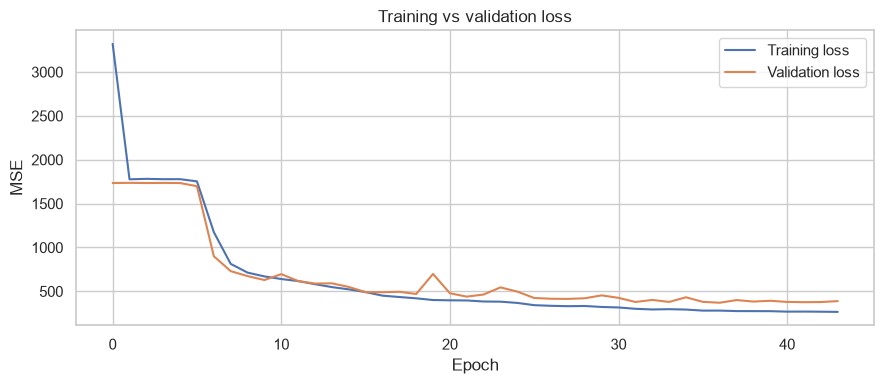

In [13]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Training vs validation loss")
plt.legend(); plt.tight_layout(); plt.show()

# 11. Evaluation helpers

Besides MAE / RMSE / R², we report the **NASA scoring function** from the C-MAPSS challenge.
It penalises *late* predictions (predicting more life than is left) more than early ones, because a late prediction is the unsafe direction. Lower is better.

In [14]:
def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)           # d > 0 means predicted too late
    return float(np.sum(np.where(d < 0, np.exp(-d / 13.0) - 1, np.exp(d / 10.0) - 1)))

def evaluate(y_true, y_pred, label):
    res = {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2":   r2_score(y_true, y_pred),
        "NASA score": nasa_score(y_true, y_pred),
    }
    print(f"{label:<34} MAE {res['MAE']:6.2f} | RMSE {res['RMSE']:6.2f} | R2 {res['R2']:7.4f} | NASA {res['NASA score']:10.1f}")
    return res

def clip_pred(p):
    return np.clip(p.reshape(-1), 0, MAX_RUL)

# Validation results (20 held-out training engines)

Validation windows come from the full run-to-failure history of each engine, so many of them are in the easy "RUL = 125" region.
The test set below is the harder and more honest benchmark.

Validation (clipped RUL)           MAE  13.80 | RMSE  19.24 | R2  0.7865 | NASA   165698.2
Validation, RUL < 125 only         MAE  16.05 | RMSE  21.59 | R2  0.6370 | NASA   152309.1


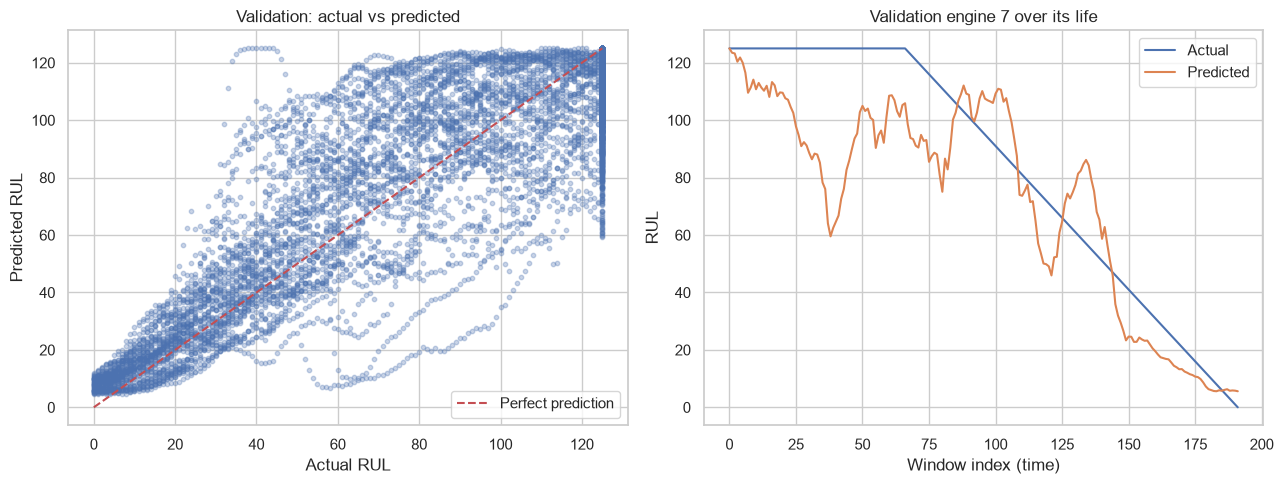

In [15]:
y_val_pred = clip_pred(model.predict(X_val, verbose=0))
val_metrics = evaluate(y_val, y_val_pred, "Validation (clipped RUL)")

# Metrics only for the part that matters most: engines close to failure
near_failure = y_val < MAX_RUL
_ = evaluate(y_val[near_failure], y_val_pred[near_failure], "Validation, RUL < 125 only")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_val, y_val_pred, alpha=0.3, s=10)
ax[0].plot([0, MAX_RUL], [0, MAX_RUL], "r--", label="Perfect prediction")
ax[0].set(xlabel="Actual RUL", ylabel="Predicted RUL", title="Validation: actual vs predicted"); ax[0].legend()

# One validation engine through time
uid = val_engines[0]
mask = (val_df.sort_values(["unit_number", "time_cycle"])["unit_number"].values >= 0)
eng_rows = val_df.sort_values(["unit_number", "time_cycle"])
lengths = eng_rows.groupby("unit_number").size().loc[val_engines]
offset = int(sum(max(n - SEQ_LEN + 1, 0) for n in lengths.loc[val_engines[val_engines < uid]]))
n_win = int(lengths.loc[uid]) - SEQ_LEN + 1
ax[1].plot(y_val[offset:offset + n_win], label="Actual")
ax[1].plot(y_val_pred[offset:offset + n_win], label="Predicted")
ax[1].set(xlabel="Window index (time)", ylabel="RUL", title=f"Validation engine {uid} over its life"); ax[1].legend()
plt.tight_layout(); plt.show()

# 12. Final test evaluation (official FD004 test set)

One prediction per test engine, compared with `RUL_FD004.txt`.

The training target was clipped at 125, so the model cannot predict above 125. We therefore report the test score against
**both** the clipped true RUL (the usual protocol in the literature) and the raw true RUL.

In [16]:
y_test_true_raw  = data_rul["RUL"].to_numpy()
y_test_true_clip = np.minimum(y_test_true_raw, MAX_RUL)
y_test_pred      = clip_pred(model.predict(X_test, verbose=0))

test_metrics_clipped = evaluate(y_test_true_clip, y_test_pred, "TEST vs clipped true RUL (125)")
test_metrics_raw     = evaluate(y_test_true_raw,  y_test_pred, "TEST vs raw true RUL")

results = pd.DataFrame({
    "unit_number":      test_ids,
    "Actual_RUL_raw":   y_test_true_raw,
    "Actual_RUL_clip":  y_test_true_clip,
    "Predicted_RUL":    y_test_pred.round(2),
})
results["Error"] = (results["Predicted_RUL"] - results["Actual_RUL_clip"]).round(2)
results["Abs_Error"] = results["Error"].abs()
display(results.head(10))

TEST vs clipped true RUL (125)     MAE  13.23 | RMSE  18.02 | R2  0.8242 | NASA     1842.2
TEST vs raw true RUL               MAE  21.92 | RMSE  29.17 | R2  0.7138 | NASA     9061.7


,unit_number,Actual_RUL_raw,Actual_RUL_clip,Predicted_RUL,Error,Abs_Error
0,1,22,22,36.259998,14.26,14.26
1,2,39,39,64.360001,25.36,25.36
2,3,107,107,118.599998,11.60,11.60
3,4,75,75,90.510002,15.51,15.51
4,5,149,125,102.029999,-22.97,22.97
5,6,78,78,118.330002,40.33,40.33
6,7,94,94,111.940002,17.94,17.94
7,8,14,14,11.320000,-2.68,2.68
8,9,99,99,110.260002,11.26,11.26
9,10,162,125,125.000000,0.00,0.00


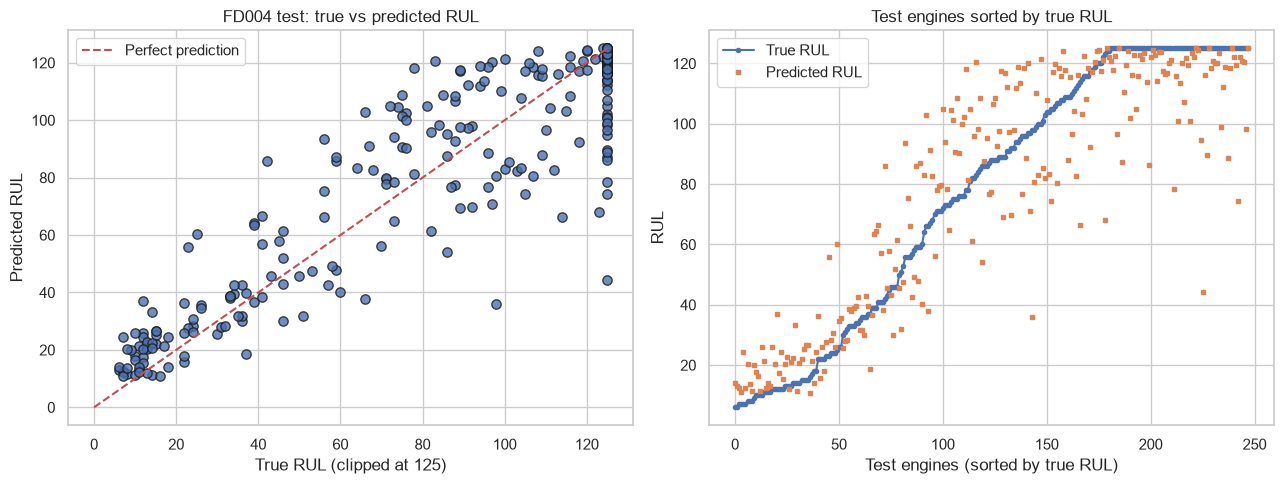

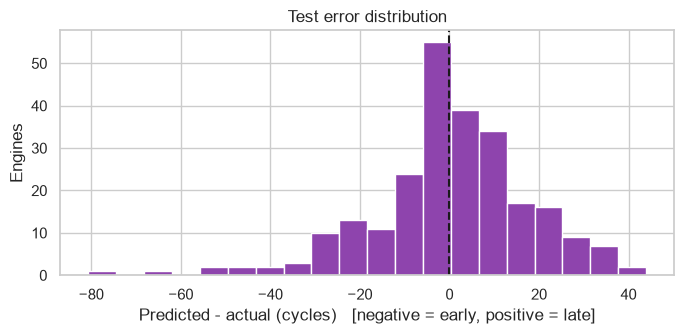

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

ax[0].scatter(y_test_true_clip, y_test_pred, alpha=0.8, edgecolors="k", s=45)
ax[0].plot([0, MAX_RUL], [0, MAX_RUL], "r--", label="Perfect prediction")
ax[0].set(xlabel="True RUL (clipped at 125)", ylabel="Predicted RUL", title="FD004 test: true vs predicted RUL")
ax[0].legend()

order = np.argsort(y_test_true_clip)
ax[1].plot(y_test_true_clip[order], "o-", ms=3, label="True RUL")
ax[1].plot(y_test_pred[order], "s", ms=3, label="Predicted RUL")
ax[1].set(xlabel="Test engines (sorted by true RUL)", ylabel="RUL", title="Test engines sorted by true RUL")
ax[1].legend()
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 3.5))
plt.hist(results["Error"], bins=20, color="#8E44AD", edgecolor="white")
plt.axvline(0, color="k", linestyle="--")
plt.xlabel("Predicted - actual (cycles)   [negative = early, positive = late]")
plt.ylabel("Engines"); plt.title("Test error distribution"); plt.tight_layout(); plt.show()

# 13. Save everything needed to reuse the model

In [18]:

import tensorflow as tf
import joblib
import json
import numpy as np

# Convert NumPy values to JSON-compatible Python values
def convert_numpy(obj):
    if isinstance(obj, dict):
        return {k: convert_numpy(v) for k, v in obj.items()}
    elif isinstance(obj, (list, tuple)):
        return [convert_numpy(v) for v in obj]
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, np.generic):
        return obj.item()
    else:
        return obj

# Save model using the supported format
tf_major_minor = tuple(
    int(x) for x in tf.__version__.split(".")[:2]
)

model_path = OUTPUT_DIR / (
    f"{DATASET}_LSTM_model.keras"
    if tf_major_minor >= (2, 12)
    else f"{DATASET}_LSTM_model.h5"
)

model.save(model_path)

# Save scaler
joblib.dump(
    scaler,
    OUTPUT_DIR / f"{DATASET}_scaler.joblib"
)

# Create config
config = dict(
    dataset=DATASET,
    seq_len=SEQ_LEN,
    roll_window=ROLL_WINDOW,
    max_rul=MAX_RUL,
    base_features=base_features,
    feature_cols=feature_cols,
    test_metrics_clipped=test_metrics_clipped,
    test_metrics_raw=test_metrics_raw,
    val_metrics=val_metrics,
)

# Convert before JSON serialization
config = convert_numpy(config)

config_path = OUTPUT_DIR / f"{DATASET}_config.json"
config_path.write_text(
    json.dumps(config, indent=2, allow_nan=False),
    encoding="utf-8"
)

# Save predictions
results.to_csv(
    OUTPUT_DIR / f"{DATASET}_LSTM_predictions.csv",
    index=False
)

print("Saved to:", OUTPUT_DIR.resolve())

for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)

Saved to: D:\Learning\NTI-HireReady AI in DA\TECHNICAL\NASA_PROJECT\FD004\outputs
 - FD004_config.json
 - FD004_LSTM_model.keras
 - FD004_LSTM_predictions.csv
 - FD004_scaler.joblib


# 14. Predict RUL for a new engine

`predict_rul` repeats the exact same steps (drop columns, rolling means, scaling, last 30 cycles) for the raw sensor history of a **single** engine.
As a safety check, its answer for test engine 1 must equal the batch prediction above.

In [19]:
def predict_rul(engine_df, model=model, scaler=scaler):
    """engine_df: raw rows (same columns as the C-MAPSS files) for ONE engine, ordered by time_cycle."""
    df = engine_df.sort_values("time_cycle").copy()
    df[num_cols] = df[num_cols].astype("float64")
    df["unit_number"] = 0
    df = add_rolling_means(df, base_features)
    df[feature_cols] = scaler.transform(df[feature_cols])
    feats = df[feature_cols].to_numpy(dtype=np.float32)
    if len(feats) < SEQ_LEN:
        feats = np.pad(feats, ((SEQ_LEN - len(feats), 0), (0, 0)), mode="edge")
    pred = model.predict(feats[-SEQ_LEN:][None, ...], verbose=0).reshape(-1)[0]
    return float(np.clip(pred, 0, MAX_RUL))

raw_test = pd.read_csv(DATA_DIR / f"test_{DATASET}.txt", sep=r"\s+", header=None, names=col_names)
single = predict_rul(raw_test[raw_test["unit_number"] == 1])
batch  = float(y_test_pred[0])
print(f"Engine 1  single-engine prediction: {single:.2f}  |  batch prediction: {batch:.2f}  |  true RUL: {y_test_true_raw[0]}")
assert abs(single - batch) < 1e-2, "Inference function does not match the batch pipeline"

Engine 1  single-engine prediction: 36.26  |  batch prediction: 36.26  |  true RUL: 22


In [20]:
import pandas as pd
import numpy as np

predicted_rul_df = pd.DataFrame({
    "Predicted_RUL": np.asarray(y_test_pred).reshape(-1)
})

output_path = OUTPUT_DIR / "FD004_Predicted_RUL.csv"
predicted_rul_df.to_csv(output_path, index=False)

print("Predicted RUL saved successfully!")
print("File:", output_path.resolve())
print("Total predictions:", len(predicted_rul_df))
print(predicted_rul_df.head(10))

Predicted RUL saved successfully!
File: D:\Learning\NTI-HireReady AI in DA\TECHNICAL\NASA_PROJECT\FD004\outputs\FD004_Predicted_RUL.csv
Total predictions: 248
   Predicted_RUL
0      36.258617
1      64.357712
2     118.600731
3      90.512070
4     102.027222
5     118.328598
6     111.939560
7      11.319398
8     110.257423
9     125.000000


In [21]:

print("===== VALIDATION PERFORMANCE =====")
print(val_metrics)

print("\n===== TEST PERFORMANCE (CLIPPED) =====")
print(test_metrics_clipped)

print("\n===== TEST PERFORMANCE (RAW) =====")
print(test_metrics_raw)

print("\n===== RESULTS COLUMNS =====")
print(results.columns.tolist())

===== VALIDATION PERFORMANCE =====
{'MAE': 13.796208, 'RMSE': 19.243532180786133, 'R2': 0.7864866677524566, 'NASA score': 165698.25}

===== TEST PERFORMANCE (CLIPPED) =====
{'MAE': 13.22567807089898, 'RMSE': 18.02108910450078, 'R2': 0.8242052096686345, 'NASA score': 1842.2074463187757}

===== TEST PERFORMANCE (RAW) =====
{'MAE': 21.91922645799575, 'RMSE': 29.16912446611492, 'R2': 0.7137966827177725, 'NASA score': 9061.681830374784}

===== RESULTS COLUMNS =====
['unit_number', 'Actual_RUL_raw', 'Actual_RUL_clip', 'Predicted_RUL', 'Error', 'Abs_Error']


In [22]:

# Display actual vs predicted RUL for the test engines
comparison = results[
    [
        "unit_number",
        "Actual_RUL_raw",
        "Predicted_RUL",
        "Error",
        "Abs_Error"
    ]
].copy()

print(comparison.head(20).to_string(index=False))

print("\nMean Absolute Error:", comparison["Abs_Error"].mean())
print(
    "Predictions within ±10 cycles:",
    f"{(comparison['Abs_Error'] <= 10).mean() * 100:.2f}%"
)

 unit_number  Actual_RUL_raw  Predicted_RUL  Error  Abs_Error
           1              22      36.259998  14.26      14.26
           2              39      64.360001  25.36      25.36
           3             107     118.599998  11.60      11.60
           4              75      90.510002  15.51      15.51
           5             149     102.029999 -22.97      22.97
           6              78     118.330002  40.33      40.33
           7              94     111.940002  17.94      17.94
           8              14      11.320000  -2.68       2.68
           9              99     110.260002  11.26      11.26
          10             162     125.000000   0.00       0.00
          11             143     118.550003  -6.45       6.45
          12               7      12.530000   5.53       5.53
          13              71      79.510002   8.51       8.51
          14             105      74.309998 -30.69      30.69
          15              12      26.059999  14.06      14.06
        

In [23]:

import numpy as np
import pandas as pd

df = results.copy()

# Positive Error means overprediction, negative means underprediction
df["Error"] = (
    df["Predicted_RUL"] - df["Actual_RUL_raw"]
)
df["Abs_Error"] = df["Error"].abs()

print("Largest 10 prediction errors:")
print(
    df.nlargest(10, "Abs_Error")[
        [
            "unit_number",
            "Actual_RUL_raw",
            "Predicted_RUL",
            "Error",
            "Abs_Error"
        ]
    ].to_string(index=False)
)

print("\nOverpredictions:", (df["Error"] > 0).sum())
print("Underpredictions:", (df["Error"] < 0).sum())
print("Within ±5 cycles:", f"{(df['Abs_Error'] <= 5).mean() * 100:.2f}%")
print("Within ±10 cycles:", f"{(df['Abs_Error'] <= 10).mean() * 100:.2f}%")
print("Within ±20 cycles:", f"{(df['Abs_Error'] <= 20).mean() * 100:.2f}%")

Largest 10 prediction errors:
 unit_number  Actual_RUL_raw  Predicted_RUL       Error  Abs_Error
         204             151      44.330002 -106.669998 106.669998
          54             176      87.209999  -88.790001  88.790001
         127             195     122.220001  -72.779999  72.779999
          19             194     125.000000  -69.000000  69.000000
         246             194     125.000000  -69.000000  69.000000
         228             189     121.459999  -67.540001  67.540001
         122             192     124.559998  -67.440002  67.440002
         241             176     110.650002  -65.349998  65.349998
         137             159      94.790001  -64.209999  64.209999
         130             165     100.970001  -64.029999  64.029999

Overpredictions: 124
Underpredictions: 124
Within ±5 cycles: 17.34%
Within ±10 cycles: 37.10%
Within ±20 cycles: 57.26%


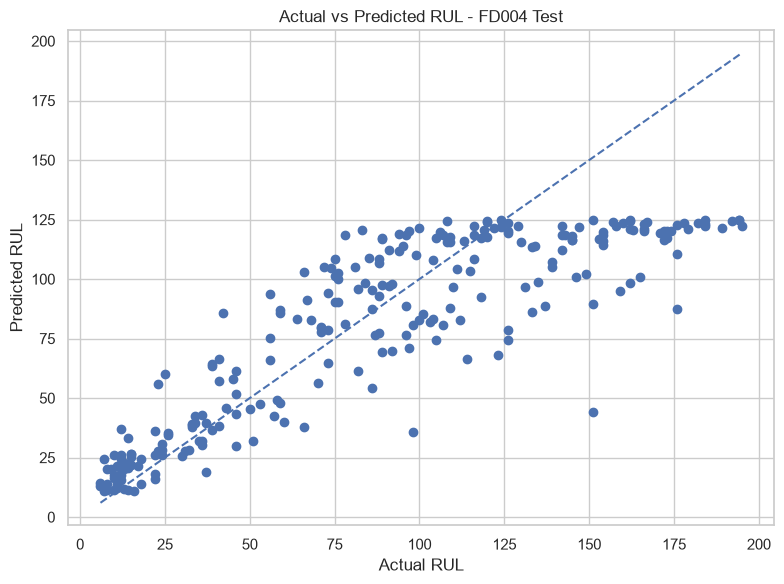

In [24]:

import matplotlib.pyplot as plt

actual = results["Actual_RUL_raw"].to_numpy()
predicted = results["Predicted_RUL"].to_numpy()

plt.figure(figsize=(8, 6))
plt.scatter(actual, predicted)

low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - FD004 Test")
plt.grid(True)
plt.tight_layout()
plt.show()

## 15. Load the final results into SQL Server

Safe to re-run: it deletes this dataset's rows first, then inserts them in one transaction (primary key = dataset + engine_id).
Run it after the results CSV has been saved above.

In [25]:
import pandas as pd
from urllib.parse import quote_plus
from sqlalchemy import create_engine, text

# ---- SQL Server settings ----
SERVER   = "localhost"
DATABASE = "EngineRUL"
DRIVER   = "ODBC Driver 18 for SQL Server"
CSV_PATH = OUTPUT_DIR / f"{DATASET}_LSTM_predictions.csv"   # DATASET = "FD004" (set in the config cell)
# -----------------------------

# 1. Read and validate
df_sql = pd.read_csv(CSV_PATH)
assert {"unit_number", "Actual_RUL_raw", "Predicted_RUL"} <= set(df_sql.columns), "Unexpected columns"
assert df_sql["unit_number"].is_unique, "Duplicate engine IDs in the CSV"
assert df_sql[["Actual_RUL_raw", "Predicted_RUL"]].notna().all().all(), "Missing values in the CSV"

df_out = pd.DataFrame({
    "dataset":       DATASET,
    "engine_id":     df_sql["unit_number"].astype(int),
    "actual_rul":    df_sql["Actual_RUL_raw"].astype(float),
    "predicted_rul": df_sql["Predicted_RUL"].astype(float),
})

# 2. Connect
odbc = (
    f"DRIVER={{{DRIVER}}};SERVER={SERVER};DATABASE={DATABASE};"
    "Trusted_Connection=yes;TrustServerCertificate=yes;"
)
engine = create_engine("mssql+pyodbc:///?odbc_connect=" + quote_plus(odbc))

# 3. Replace this dataset's rows in ONE transaction (all or nothing)
with engine.begin() as conn:
    conn.execute(text("DELETE FROM dbo.rul_predictions WHERE dataset = :ds"), {"ds": DATASET})
    df_out.to_sql("rul_predictions", conn, schema="dbo", if_exists="append", index=False)

# 4. Verify
with engine.connect() as conn:
    n = conn.execute(
        text("SELECT COUNT(*) FROM dbo.rul_predictions WHERE dataset = :ds"), {"ds": DATASET}
    ).scalar()
print(f"{DATASET}: {len(df_out)} rows sent, {n} rows now in SQL Server")
assert n == len(df_out), "Row count mismatch!"


FD004: 248 rows sent, 248 rows now in SQL Server


# Notes

* **No leakage:** engines are split before scaling; the scaler is fitted on training engines only; rolling means look backwards only.
* **Fair test:** the test set is never used for training, early stopping, or scaling.
* **Ideas to improve further:** try a 1D-CNN + LSTM, a longer window (50), several random seeds averaged, or an asymmetric loss that punishes late predictions more.